# Forecast 2 — Evapotranspiration and Streamflow Forecasting

CEE 306: Hydrology — Water and Climate | Spring 2026

This team forecast estimates Stony Brook streamflow using a linear reservoir model and evapotranspiration calculations. The notebook retains the original coursework code and saved results.

**Forecast Team Name:** `<HBO>`

**Names:** `<Muhammad Omer, Sayfullo Saidov, Wunnyuriti Ziblim>`

**Forecasted Dates:** `Friday April 10th - Sunday April 12th`

## Python Imports

In [1]:
import pandas as pd
import numpy as np
import json, requests
import matplotlib.pyplot as plt
import datetime

## Recent Hydrometeorological Observations and Weather Forecasts

In [2]:
## get the forecast for temperature and precipitation
headers = {
'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/71.0.3578.98 Safari/537.36',
'Accept' : 'text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8',
'Accept-Language' : 'en-US,en;q=0.5',
'Accept-Encoding' : 'gzip',
'DNT' : '1', # Do Not Track Request Header
'Connection' : 'close' }
url = requests.get("https://api.weather.gov/gridpoints/PHI/63,95/", headers=headers)

data_json = json.loads(url.text)

data = pd.DataFrame(columns=('DateTime','Precip [mm]','Temp [C]'))
for i in range(12):
    data.loc[i] = [data_json['properties']['quantitativePrecipitation']['values'][i]['validTime'],
                   data_json['properties']['quantitativePrecipitation']['values'][i]['value'],
                   data_json['properties']['temperature']['values'][i]['value']]

# note the cumulative sum calculations and conversions below
data['DateTime'] = data['DateTime'].str.slice(stop=16)
data['cum_precip_mm'] = data['Precip [mm]'].cumsum()
data['Precip_ft'] = data['Precip [mm]']*0.00328084
data['Precip_in'] = data['Precip [mm]']*0.0393701
data['cum_precip_in'] = data['Precip_in'].cumsum()
data

,DateTime,Precip [mm],Temp [C],cum_precip_mm,Precip_ft,Precip_in,cum_precip_in
0,2026-04-09T14:00,0,5,0,0.0,0.0,0.0
1,2026-04-09T18:00,0,7.222222,0,0.0,0.0,0.0
2,2026-04-10T00:00,0,9.444444,0,0.0,0.0,0.0
3,2026-04-10T06:00,0,11.666667,0,0.0,0.0,0.0
4,2026-04-10T12:00,0,12.222222,0,0.0,0.0,0.0
5,2026-04-10T18:00,0,13.333333,0,0.0,0.0,0.0
6,2026-04-11T00:00,0,13.888889,0,0.0,0.0,0.0
7,2026-04-11T06:00,0,12.777778,0,0.0,0.0,0.0
8,2026-04-11T12:00,0,11.111111,0,0.0,0.0,0.0
9,2026-04-11T18:00,0,9.444444,0,0.0,0.0,0.0


In [3]:
## now let's get past week of streamflow and precipitation - using the same url process as before
period = "P7D"
# agian, feel free to print and look at those URLs

# streamflow from Stony Brook
flow_url = "https://nwis.waterdata.usgs.gov/nwis/iv/?format=rdb&sites=01401000&period="+period+"&parameterCd=00060&siteStatus=all"
StonyBrook = pd.read_csv(flow_url, skiprows=28, sep='\t', header=None)
StonyBrook.columns = ["agency_cd","site_no","datetime_stony","tz_cd","flow_cfs","194689_00060_cd"]

# precip from Skillman
precip_url = "https://nwis.waterdata.usgs.gov/nwis/iv/?format=rdb&sites=402504074414201&period="+period+"&parameterCd=00045&siteStatus=all"
Skillman = pd.read_csv(precip_url, skiprows=28, sep='\t', header=None)
Skillman.columns = ["agency_cd","site_no","datetime_skill","tz_cd","precip_in","Cumulative_Precip"]
Skillman['cum_precip_in'] = Skillman['precip_in'].cumsum()

# air temperature from Trenton
airtemp_url = "https://waterdata.usgs.gov/nwis/uv?cb_00021=on&format=rdb&site_no=401121074452101&period="+period
Trenton = pd.read_csv(airtemp_url, skiprows=28, sep='\t', header=None)
Trenton.columns = ['agency_cd','site_no',"datetime_trent","tz",'airTemp_F','description']

## if you want, uncomment the below code to see the csv url links, and a sample of the dataframes
print(f'Streamflow csv URL: {flow_url}')
print(StonyBrook.head(5),'\n')
print(f'Precipitation csv URL: {precip_url}')
print(Skillman.head(5),'\n')
print(f'Air temperature URL: {airtemp_url}')
print(Trenton.head(5),'\n')

Streamflow csv URL: https://nwis.waterdata.usgs.gov/nwis/iv/?format=rdb&sites=01401000&period=P7D&parameterCd=00060&siteStatus=all
  agency_cd  site_no    datetime_stony tz_cd  flow_cfs 194689_00060_cd
0      USGS  1401000  2026-04-02 18:30   EDT      25.3               P
1      USGS  1401000  2026-04-02 18:45   EDT      25.3               P
2      USGS  1401000  2026-04-02 19:00   EDT      25.3               P
3      USGS  1401000  2026-04-02 19:15   EDT      25.3               P
4      USGS  1401000  2026-04-02 19:30   EDT      25.3               P 

Precipitation csv URL: https://nwis.waterdata.usgs.gov/nwis/iv/?format=rdb&sites=402504074414201&period=P7D&parameterCd=00045&siteStatus=all
  agency_cd          site_no    datetime_skill tz_cd  precip_in  \
0      USGS  402504074414201  2026-04-02 18:30   EDT        0.0   
1      USGS  402504074414201  2026-04-02 18:45   EDT        0.0   
2      USGS  402504074414201  2026-04-02 19:00   EDT        0.0   
3      USGS  402504074414201  20

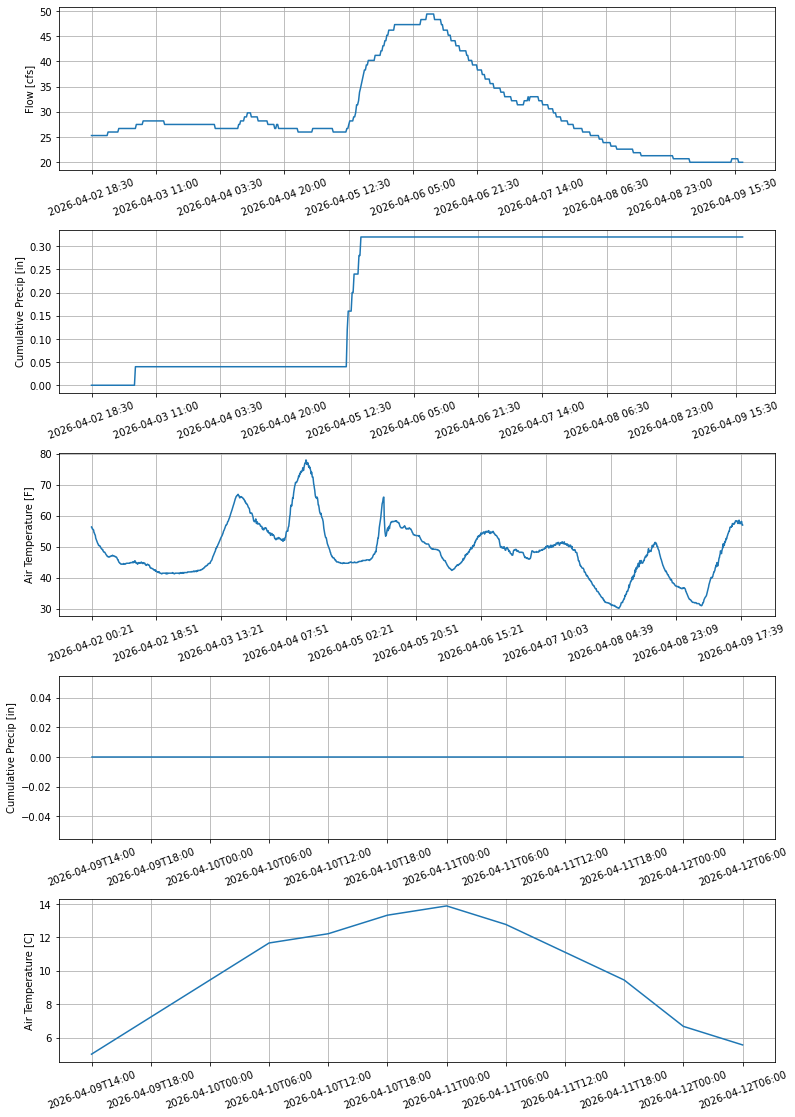

In [4]:
## plot data
## set up figure with 4 plots
fig, axs = plt.subplots(5,figsize=(12,16))

## plot past streamflow
axs[0].plot(StonyBrook['datetime_stony'],StonyBrook['flow_cfs'])
axs[0].set_xticks(StonyBrook['datetime_stony'][::len(StonyBrook['datetime_stony']) // 10])
axs[0].set_ylabel('Flow [cfs]')

## plot past precipitation
axs[1].plot(Skillman['datetime_skill'],Skillman['cum_precip_in'])
axs[1].set_xticks(Skillman['datetime_skill'][::len(Skillman['datetime_skill']) // 10])
axs[1].set_ylabel('Cumulative Precip [in]')

## plot past air temperature
axs[2].plot(Trenton['datetime_trent'],Trenton['airTemp_F'])
axs[2].set_xticks(Trenton['datetime_trent'][::len(Trenton['datetime_trent']) // 10])
axs[2].set_ylabel('Air Temperature [F]')

## plot forecast precip
axs[3].plot(data['DateTime'],data['cum_precip_in'])
axs[3].set_ylabel('Cumulative Precip [in]')

## plot forecast air temp
axs[4].plot(data['DateTime'],data['Temp [C]'])
axs[4].set_ylabel('Air Temperature [C]')

# put space between plots
fig.tight_layout(pad=4.0)

# add a grid and rotate the x-axis labels on each plot
for i in range(5):
    axs[i].grid()
    axs[i].tick_params(axis='x', labelrotation = 20)

## Streamflow Forecast Model

In [5]:
## Q1.1, DAYMET URL
url = "https://daymet.ornl.gov/single-pixel/send/saveData?lat=40.3573&lon=-74.6672&start=2020-07-01&end=2020-08-01&format=csv"

# read in the data much like before
weather = pd.read_csv(url, skiprows=6)
weather.head()

,year,yday,dayl (s),prcp (mm/day),srad (W/m^2),swe (kg/m^2),tmax (deg c),tmin (deg c),vp (Pa)
0,2020,183,53375.69,3.02,270.03,0.0,28.44,18.06,2071.17
1,2020,184,53335.59,0.00,472.14,0.0,33.54,17.20,1952.25
2,2020,185,53292.05,12.28,313.90,0.0,33.67,20.03,2341.30
3,2020,186,53245.11,0.00,375.07,0.0,31.59,20.25,2373.97
4,2020,187,53194.80,0.00,422.31,0.0,34.43,20.40,2395.28


Mean ET0 over past 10 days: 2.93 mm/day = 0.1154 in/day
NSE   = 0.645
PBIAS = -5.0%
RMSE  = 4.8 cfs


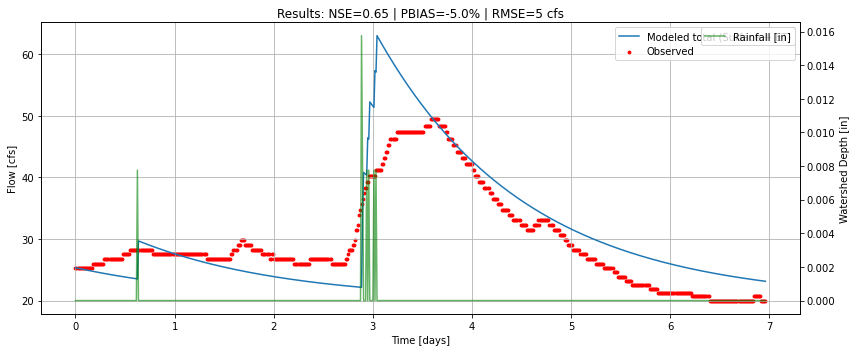

In [6]:

#1. GET ET (reusing HW2 code, fixed)


today = datetime.datetime.today()
start_et = (today - datetime.timedelta(days=10)).strftime('%Y-%m-%d')
end_et = today.strftime('%Y-%m-%d')
url_et = f"https://daymet.ornl.gov/single-pixel/send/saveData?lat=40.3573&lon=-74.6672&start={start_et}&end={end_et}&format=csv"
weather = pd.read_csv(url_et, skiprows=6)

T_min = weather['tmin (deg c)']
T_max = weather['tmax (deg c)']
T_mean = (T_min + T_max) / 2

# constants
u2     = 2
albedo = 0.23
sigma  = 4.903e-9
a_s    = 0.25
b_s    = 0.55
gamma  = 0.066

# solar geometry
J = pd.to_datetime(weather['year']*1000 + weather['yday'], format='%Y%j').dt.dayofyear
phi = np.deg2rad(40.3573)
G_sc = 0.0820
d_r       = 1 + 0.033 * np.cos(2*np.pi*J/365)
delta_solar = 0.409 * np.sin(2*np.pi*J/365 - 1.39)
omega_s   = np.arccos(-np.tan(phi) * np.tan(delta_solar))
R_a       = (24*60/np.pi) * G_sc * d_r * (
    omega_s * np.sin(phi) * np.sin(delta_solar) +
    np.cos(phi) * np.cos(delta_solar) * np.sin(omega_s)
)

# observed solar radiation
R_s  = weather['srad (W/m^2)'] * weather['dayl (s)'] / 1e6
R_so = (a_s + b_s) * R_a
R_ns = (1 - albedo) * R_s

def calc_e0(T):
    return 0.6108 * np.exp((17.27*T) / (T + 237.3))

e_a = calc_e0(T_min - 2)
R_nl = sigma * (
    ((T_max+273.16)**4 + (T_min+273.16)**4) / 2
) * (0.34 - 0.14*np.sqrt(e_a)) * (1.35*(R_s/R_so) - 0.35)
R_n = R_ns - R_nl

e_s          = (calc_e0(T_max) + calc_e0(T_min)) / 2
delta_vapor  = 4096 * e_s / (T_mean + 237.3)**2

ET0 = (
    0.408 * delta_vapor * R_n +
    gamma * (900 / (T_mean + 273)) * u2 * (e_s - e_a)
) / (delta_vapor + gamma * (1 + 0.34 * u2))

ET_in_per_day = ET0 * 0.0393701          # mm/day to in/day
ET_daily_avg  = float(np.mean(ET_in_per_day))  # single average
print(f"Mean ET0 over past 10 days: {np.mean(ET0):.2f} mm/day = {ET_daily_avg:.4f} in/day")


#2. PARAMETERS that we keep fixed


area      = 44.5 * 2.788e7   # ft^2
inches_per_foot = 12
dt        = 0.25 / 24        # 15-min timestep [days]
T_star    = 1.5            # surface residence time [days]
runoff_coeff = 0.2

n_tsteps = len(StonyBrook)
t        = np.arange(n_tsteps) * dt

# converting observed flow to watershed depth
StonyBrook['flow_cfs'] = pd.to_numeric(StonyBrook['flow_cfs'], errors='coerce')
StonyBrook['flow_in']  = StonyBrook['flow_cfs'] * inches_per_foot * 900 / area
q_obs = StonyBrook['flow_in'].values.astype(float)

# baseflow
#(even though we are not using GW, we can still consider some baseflow happening when dry season continues -  reusing from Forecast 1)
baseflow = np.nanmin(q_obs)
q_quick  = q_obs - baseflow
q_quick[q_quick < 0] = 0

# precipitation
Skillman['precip_in'] = pd.to_numeric(Skillman['precip_in'], errors='coerce').fillna(0)
P_series = Skillman['precip_in'].values
if len(P_series) < n_tsteps: #we need to make sure that the data row numbers match to each other
    P_series = np.pad(P_series, (0, n_tsteps - len(P_series)), 'constant')
else:
    P_series = P_series[:n_tsteps]

# effective rainfall after minusing ET
w = P_series * runoff_coeff
ET_per_ts = ET_daily_avg * dt
w = np.maximum(P_series - ET_per_ts, 0.0) * runoff_coeff

lag = 15   # in real life, obviously there is a time between rain happening and sensor water level recording. so we are assuming that in the model

w = np.roll(w, lag)
w[:lag] = 0.0   # zero-fill to avoid error



# 3. LINEAR RESERVOIR MODEL (NO GW)


Q_surf = np.zeros(n_tsteps)
V_surf = np.zeros(n_tsteps)

# initial conditions considering baseflow

V_surf[0] = q_quick[0] * T_star
Q_surf[0] = q_quick[0]

# model loop
for i in range(1, n_tsteps):
    Q_surf[i] = V_surf[i-1] / T_star
    V_surf[i] = max(V_surf[i-1] + (w[i] - Q_surf[i]) * dt, 0)



# 4. TOTAL FLOW to CFS to have it on the graph


Q_total_in  = Q_surf + baseflow
Q_model_cfs = Q_total_in * area / (inches_per_foot * 900)
Q_obs_cfs   = q_obs * area / (inches_per_foot * 900)


# 5. VALIDATION METRICS: several of them


mask     = ~np.isnan(Q_obs_cfs) & ~np.isnan(Q_model_cfs)
obs_v    = Q_obs_cfs[mask]
mod_v    = Q_model_cfs[mask]
obs_mean = obs_v.mean()

NSE   = 1 - np.sum((obs_v - mod_v)**2) / np.sum((obs_v - obs_mean)**2)
PBIAS = 100 * np.sum(obs_v - mod_v) / np.sum(obs_v)
RMSE  = np.sqrt(np.mean((obs_v - mod_v)**2))

print(f"NSE   = {NSE:.3f}")
print(f"PBIAS = {PBIAS:.1f}%")
print(f"RMSE  = {RMSE:.1f} cfs")



# 6.  PLOT to compare observed flow vs the model

#Forecast 2 employs linear reservoir combined with ET 



t_obs = np.arange(len(StonyBrook)) * dt

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.scatter(t_obs, Q_obs_cfs, color='red', s=8, label='Observed')
ax1.plot(t, Q_model_cfs, label='Modeled total (Surface + ET)', linewidth=1.5)
ax1.set_xlabel('Time [days]')
ax1.set_ylabel('Flow [cfs]')
ax1.set_title(f'Results: NSE={NSE:.2f} | PBIAS={PBIAS:.1f}% | RMSE={RMSE:.0f} cfs')
ax1.legend()
ax1.grid()

ax2 = ax1.twinx()
ax2.plot(t, w, color='green', alpha=0.6, label='Rainfall [in]')
ax2.set_ylabel('Watershed Depth [in]')
ax2.legend()

plt.tight_layout()
plt.show()

Friday: 20 cfs
Saturday: 20 cfs
Sunday: 20 cfs


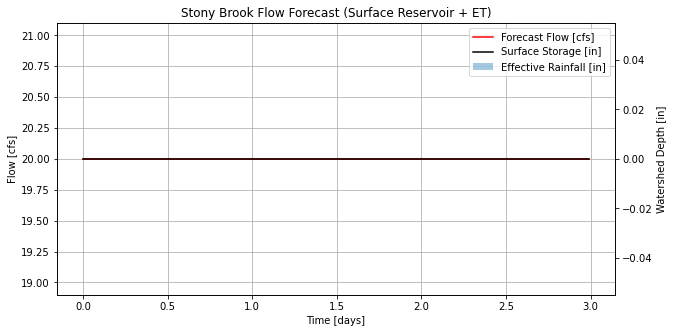

In [9]:
# FORECAST (SURFACE RESERVOIR + ET)

forecast_days = 3
n_tsteps_f    = int(forecast_days / dt)
time_forecast = np.arange(n_tsteps_f) * dt

# initializing to zero
V_f = np.zeros(n_tsteps_f)
q_f = np.zeros(n_tsteps_f)

# initial condition: last observed quick flow (baseflow already separated)
V_f[0] = q_quick[-1] * T_star
q_f[0] = q_quick[-1]

# forecast precipitation to effective rainfall (same method as before)
steps_per_row = int((6/24) / dt)   # NWS gives 6-hr intervals
forecast_precip = data['Precip_in'].values * runoff_coeff
w_f = np.repeat(forecast_precip / steps_per_row, steps_per_row)
w_f = w_f[:n_tsteps_f]

# subtracting ET per timestep
ET_per_ts = ET_daily_avg * dt
w_f = np.maximum(w_f - ET_per_ts, 0.0)

# Again the Euler linear reservoir — same loop as hindcast
for i in range(1, n_tsteps_f):
    q_f[i] = V_f[i-1] / T_star
    V_f[i] = max(V_f[i-1] + (w_f[i] - q_f[i]) * dt, 0)

# adding baseflow back, converting to cfs
q_f_cfs = (q_f + baseflow) * area / (inches_per_foot * 900)

# daily averages
steps_per_day = int(1 / dt)
day_names = ['Friday', 'Saturday', 'Sunday']
for day in range(forecast_days):
    s = day * steps_per_day
    e = s + steps_per_day
    print(f"{day_names[day]}: {np.mean(q_f_cfs[s:e]):.0f} cfs")

# ploting the final predicted forecasted flow result
#(no precipitation, so it is horizontal, but if there was precipitation, it would have been exponential decay)

#So, right now it is staying nearly constant at the baseflow value that we found from the minimum observed from the past data. 
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(time_forecast, q_f_cfs, color='red', label='Forecast Flow [cfs]')
ax1.set_xlabel('Time [days]')
ax1.set_ylabel('Flow [cfs]')
ax1.grid()

ax2 = ax1.twinx()
ax2.bar(time_forecast, w_f, width=dt*0.8, alpha=0.4, label='Effective Rainfall [in]')
ax2.plot(time_forecast, V_f, color='black', label='Surface Storage [in]')
ax2.set_ylabel('Watershed Depth [in]')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2)
plt.title("Stony Brook Flow Forecast (Surface Reservoir + ET)")
plt.show()

**Friday:** `<20 cfs>` <br>
**Saturday:** `<20 cfs>` <br>
**Sunday:** `<19.75 cfs>`

### Forecast Methodology

`<This forecast was built using three main components: (1) ET estimation, (2) a linear reservoir model, and (3) observed and forecasted hydrometeorological data.`
`For ET, we used the FAO-56 Penman-Monteith method, implemented with recent DAYMET climate data (past 10 days) for the Stony Brook watershed (lat 40.3573°, lon -74.6672°). This method calculates reference ET₀ using net radiation (R_n), vapor pressure deficit (e_s − e_a), and wind speed (u₂ = 2 m/s), yielding a mean ET rate in mm/day that was converted to in/day for consistency.`
`Observed streamflow (15-min intervals) was pulled from USGS gauge 01401000 (Stony Brook), observed precipitation from USGS gauge 402504074414201 (Skillman), and air temperature from USGS Trenton. A 7-day period was used for model calibration (hindcast).`
`The linear reservoir model separates baseflow (minimum observed flow) from quickflow, then applies effective rainfall — computed as max(P − ET_per_timestep, 0) × runoff coefficient — through a single-reservoir Euler formula with a surface residence or response time of T_star = 1.5 days.`
`For the 3-day forecast (Friday–Sunday), NWS gridpoint forecast precipitation (6-hr intervals, PHI/63,95) and the computed mean ET value were used as forcing. The reservoir model was then run forward to produce daily average flow estimates.>`

### Changes from the Previous Forecast

`<The key difference from the previous forecast is the physically-based calculation of evapotranspiration (ET) rather than treating it as a fixed constant fraction. In our prior forecast, ET was represented as a simple scalar multiplied by precipitation (e.g., ET_factor = 0.8), which does not vary with weather conditions. This makes the ET loss term dynamic rather than static, improving the result.`

`Compared to the prior forecast, this approach is more quantitative and sensitive to environmental conditions, but it introduces new assumptions (fixed wind speed, albedo, and runoff coefficient) that limit its precision. >`

### Comparison with Previous Forecasts

`<This forecast is better than previous forecasts because of its quantitative calculation of the evapotranspiration. Our first forecast was not governed by a specific model, and our second forecast used the linear reservoir model. This linear reservoir model used an ET constant of 0.8. Since ET is a physically complex process rather than a constant fraction, inaccuracy in the previous forecast likely came from this simplification. Comparatively, our forecast 2 has a basis in physical understanding of ET through the FAO-56 method of calculating ET. This method incorporates net solar radiation, vapor pressure values, and wind speed among other processes to apply the ET scientifically. We were able to input observed temperature and temporal data to fine tune our ET calculations, specifically for longwave radiation and vapor pressure values. Since our model acknowledges that ET changes depending on various environmental inputs, we expect it to be more accurate.>`

`As the task allowed us to employ either ET or GW for the forecast, we chose ET since we thought GW would have been a better choice if the forecast was for much longer period to see the exponential graph. While initially, we included both ET and GW, we understood that the model is mostly influenced by the surface flow, and there was no precipitation expected in upcoming days. So, we sticked to ET. However, in order to at least acknowledge the role, though minimal, of the groundwater, we again used baseflow formula that we used in Forecast 1. This way, we believe that our linear reservoir model is equipped with ET and a baseflow. The better model could have been the one that uses both and predicts forecast of longer period.`

## Model Validation

In [8]:
### 5. VALIDATION METRICS (repeated from above for clarification)


mask     = ~np.isnan(Q_obs_cfs) & ~np.isnan(Q_model_cfs)
obs_v    = Q_obs_cfs[mask]
mod_v    = Q_model_cfs[mask]
obs_mean = obs_v.mean()

NSE   = 1 - np.sum((obs_v - mod_v)**2) / np.sum((obs_v - obs_mean)**2)
PBIAS = 100 * np.sum(obs_v - mod_v) / np.sum(obs_v)
RMSE  = np.sqrt(np.mean((obs_v - mod_v)**2))

print(f"NSE   = {NSE:.3f}")
print(f"PBIAS = {PBIAS:.1f}%")
print(f"RMSE  = {RMSE:.1f} cfs")

NSE   = 0.645
PBIAS = -5.0%
RMSE  = 4.8 cfs


`<To validate our model, we employed three scoring metrics: Nash-Sutcliffe Efficiency (NSE), percent bias (PBIAS), and root mean squared error (RMSE). The NSE evaluates the overall accuracy of the model’s prediction and is ubiquitous in hydrological evaluation. However, since the NSE is less sensitive to outliers, the RMSE was considered to quantify the effect of outliers, and the PBIAS gave insight into whether such discrepancies were underestimates or overestimates. The specific quantification of PBIAS and RMSE led us to change some parameters in order to minimize the underestimation of the model and minimize the variance in the data. These validation metrics reveal that our model has generally low predictive power (as our NSE is far from 1), with systematic underestimates of data (since our PBIAS is negative). Our model is off by 4.8 cfs on average. However, when we compare validation metrics to our previous model, this ET model is more accurate and has higher predictive power. Our NSE is closer to 1 than the previous model NSE of -0.9546, our PBIAS is closer to 0 than the previous model value of 46.37%, and the RMSE is way lower than the previous RMSE of 126.88 cfs. This inaccuracy is expected. Firstly, we made many assumptions when crafting our ET calculation through the FAO-56 method. We did not use any quantitative measurements or calculations for albedo, guessed a dew point offset (K_0), and did not account for the effect of pressure and temperature on our psychometric constant.  We also did not account for snowpack melt or groundwater input and drainage with a concrete analytical model, instead using constants for a runoff coefficient and a constant groundwater input. We also still used a T-star value, which remained constant throughout the duration of the model, and is generic regardless without ties to specific physical processes. This explains the persisting uncertainty in our model shown through our validation metrics.>`

# Acknowledgement

`We used AI to debug some issues we had with unit conversion and matching the number of rows and data timesteps conversions. Most codes were reused from previous homework and readjusted to match the goal of this forecast assignment`